In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../ecommerce_dataset_updated.csv")
df = df.rename(columns={"Price (Rs.)": "Price",
                        "Discount (%)": "Discount",
                        "Final_Price(Rs.)": "Final_Price"})

df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"], dayfirst=True)
df = df.sort_values("Purchase_Date").set_index("Purchase_Date")

# Your two objective answers
top_cat = df["Category"].value_counts().idxmax()
top_pay = df["Payment_Method"].value_counts().idxmax()
print("Top category:", top_cat, "| Top payment method:", top_pay)
print("Date range:", df.index.min(), "to", df.index.max())

Top category: Home & Kitchen | Top payment method: Credit Card
Date range: 2024-01-01 00:00:00 to 2024-11-21 00:00:00


## line chart


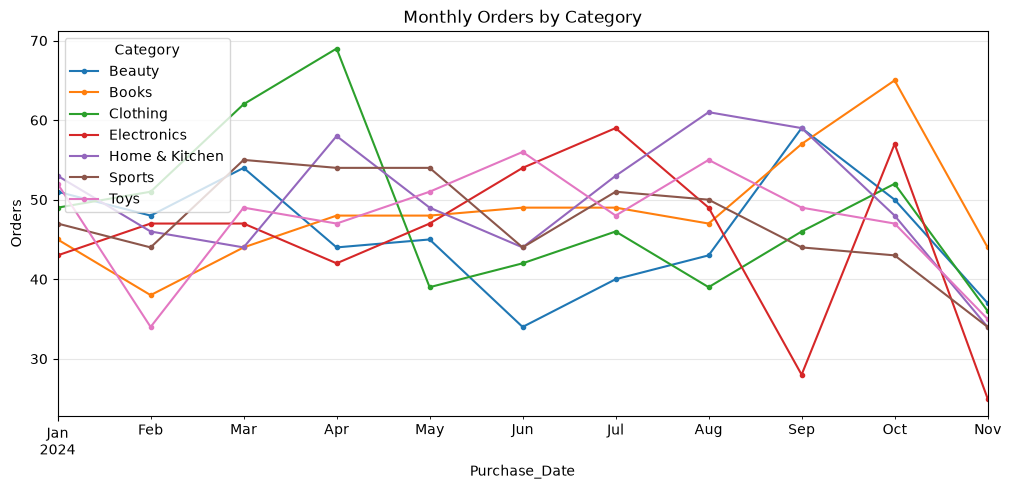

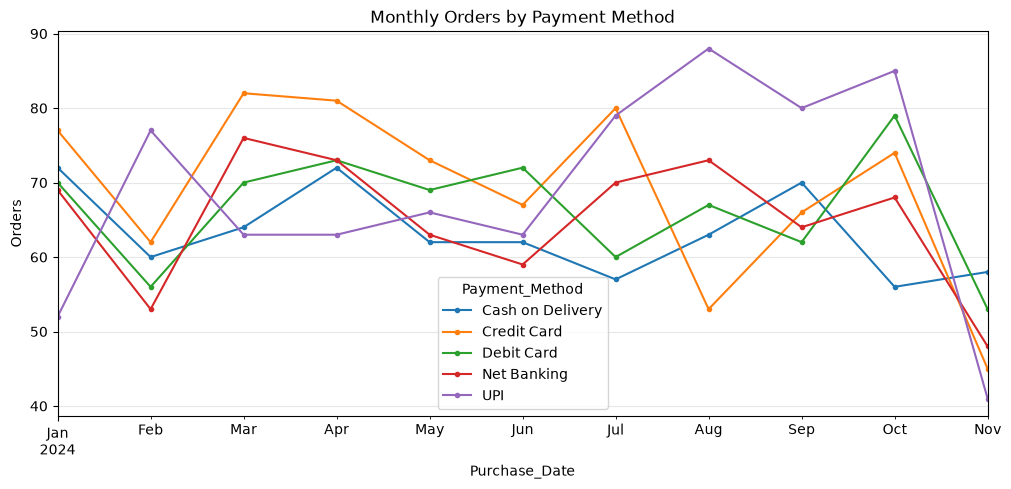

In [11]:
# Orders per month for each category
cat_m = df.groupby([pd.Grouper(freq="ME"), "Category"]).size().unstack(fill_value=0)
cat_m.plot(figsize=(12, 5), marker="o", markersize=3)
plt.title("Monthly Orders by Category"); plt.ylabel("Orders"); plt.grid(alpha=0.3)
plt.show()

# Orders per month for each payment method
pay_m = df.groupby([pd.Grouper(freq="ME"), "Payment_Method"]).size().unstack(fill_value=0)
pay_m.plot(figsize=(12, 5), marker="o", markersize=3)
plt.title("Monthly Orders by Payment Method"); plt.ylabel("Orders"); plt.grid(alpha=0.3)
plt.show()

## Area Chart

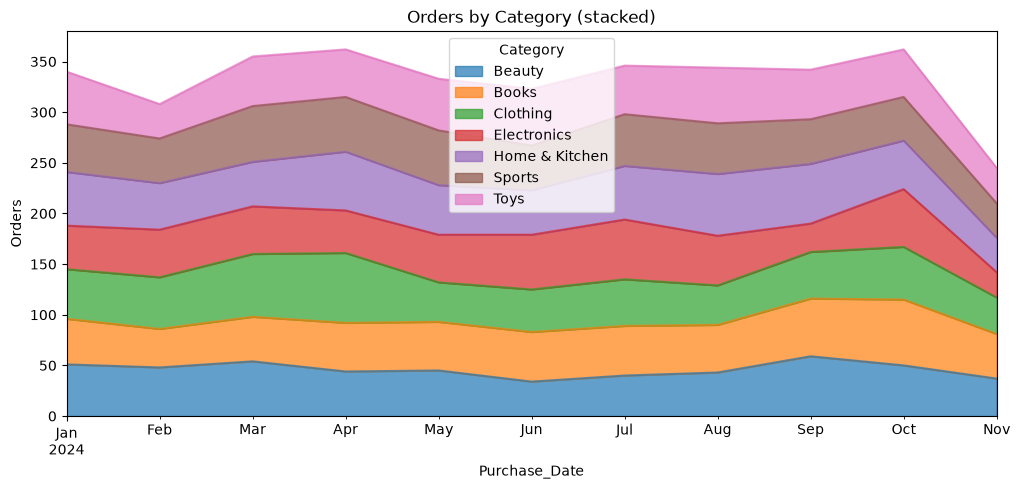

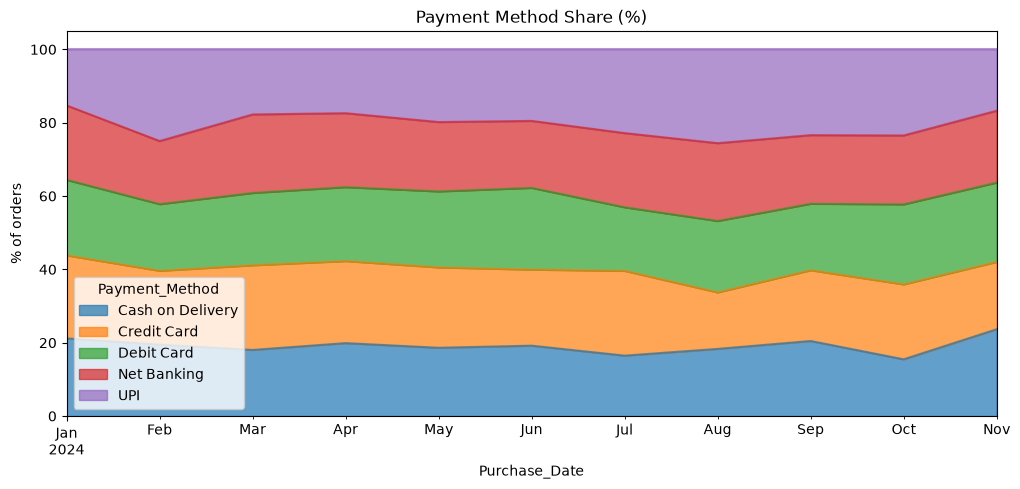

In [12]:
cat_m.plot.area(figsize=(12, 5), alpha=0.7)
plt.title("Orders by Category (stacked)"); plt.ylabel("Orders"); plt.show()

# Percent share version: easier for seeing who is gaining ground
(pay_m.div(pay_m.sum(axis=1), axis=0) * 100).plot.area(figsize=(12, 5), alpha=0.7)
plt.title("Payment Method Share (%)"); plt.ylabel("% of orders"); plt.show()

## moving-average plots

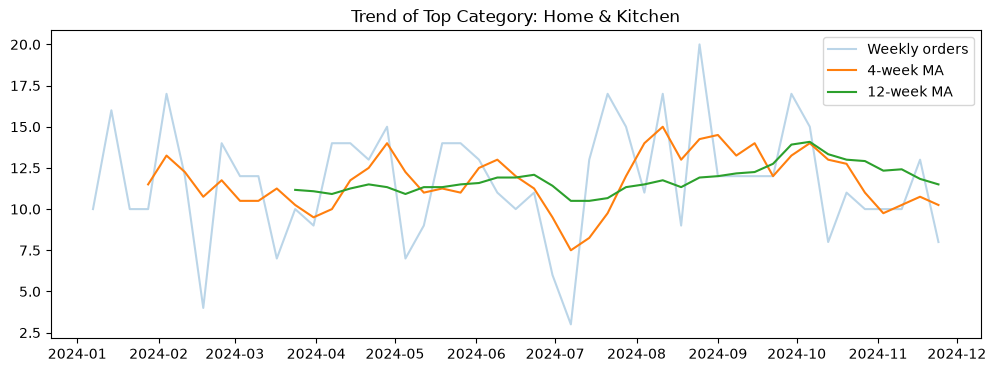

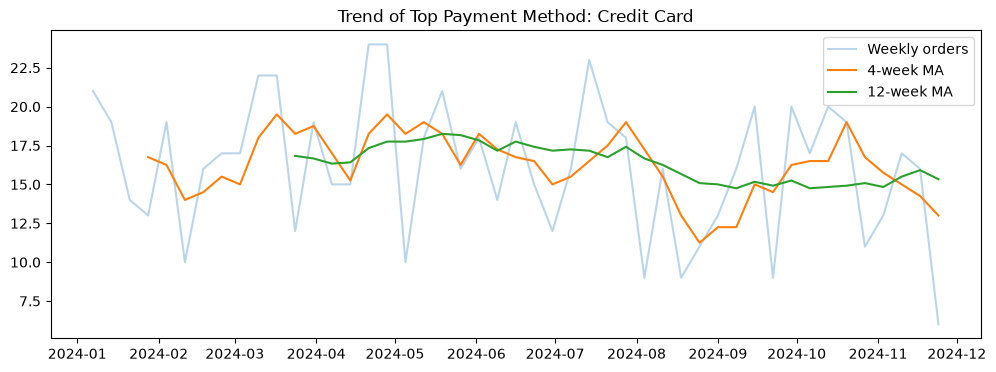

In [13]:
# Top category
s = df[df["Category"] == top_cat].resample("W").size()
plt.figure(figsize=(12, 4))
plt.plot(s, alpha=0.3, label="Weekly orders")
plt.plot(s.rolling(4).mean(),  label="4-week MA")
plt.plot(s.rolling(12).mean(), label="12-week MA")
plt.title(f"Trend of Top Category: {top_cat}"); plt.legend(); plt.show()

# Top payment method
s = df[df["Payment_Method"] == top_pay].resample("W").size()
plt.figure(figsize=(12, 4))
plt.plot(s, alpha=0.3, label="Weekly orders")
plt.plot(s.rolling(4).mean(),  label="4-week MA")
plt.plot(s.rolling(12).mean(), label="12-week MA")
plt.title(f"Trend of Top Payment Method: {top_pay}"); plt.legend(); plt.show()

## Scatter plot

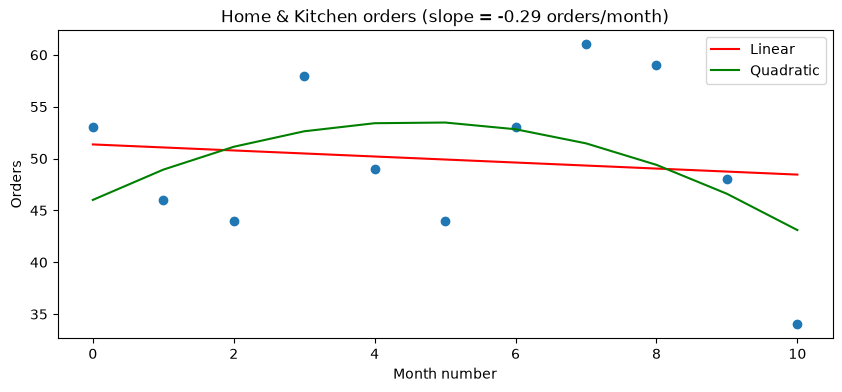

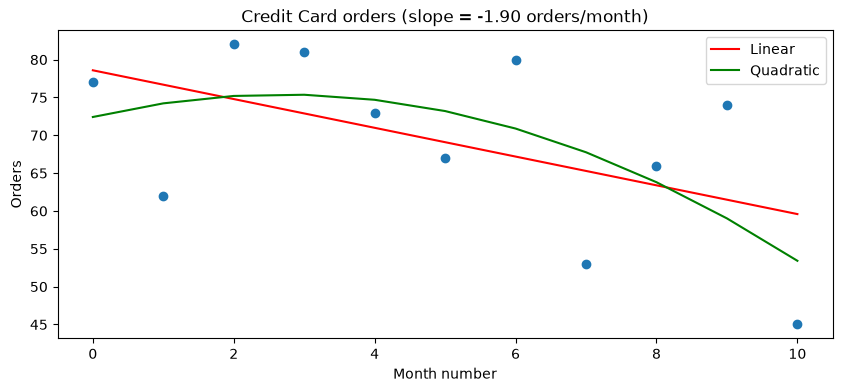

In [14]:
def trend_scatter(series, title):
    x = np.arange(len(series)); y = series.values.astype(float)
    plt.figure(figsize=(10, 4))
    plt.scatter(x, y)
    plt.plot(x, np.polyval(np.polyfit(x, y, 1), x), "r", label="Linear")
    plt.plot(x, np.polyval(np.polyfit(x, y, 2), x), "g", label="Quadratic")
    slope = np.polyfit(x, y, 1)[0]
    plt.title(f"{title} (slope = {slope:+.2f} orders/month)")
    plt.xlabel("Month number"); plt.ylabel("Orders"); plt.legend(); plt.show()

trend_scatter(df[df["Category"] == top_cat].resample("ME").size(), f"{top_cat} orders")
trend_scatter(df[df["Payment_Method"] == top_pay].resample("ME").size(), f"{top_pay} orders")

## Bubble chart

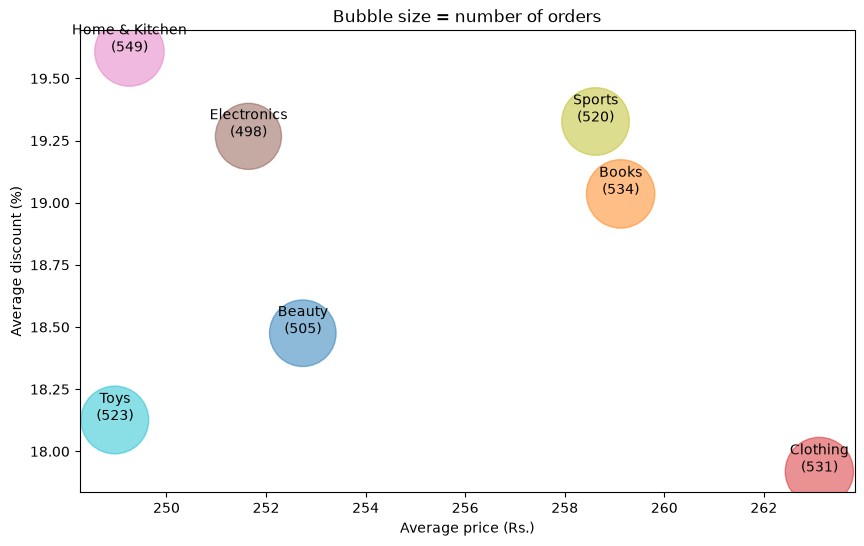

In [15]:
cat = df.groupby("Category").agg(orders=("Price", "size"),
                                 avg_price=("Price", "mean"),
                                 avg_discount=("Discount", "mean"))

plt.figure(figsize=(10, 6))
plt.scatter(cat["avg_price"], cat["avg_discount"],
            s=cat["orders"] / cat["orders"].max() * 2500,
            alpha=0.5, c=range(len(cat)), cmap="tab10")
for name, r in cat.iterrows():
    plt.annotate(f"{name}\n({int(r['orders'])})", (r["avg_price"], r["avg_discount"]), ha="center")
plt.xlabel("Average price (Rs.)"); plt.ylabel("Average discount (%)")
plt.title("Bubble size = number of orders")
plt.show()